In [2]:
# Cell 1: Import libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications.mobilenet import preprocess_input

print("Libraries imported successfully!")


2026-01-21 16:57:47.276524: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769014667.630257      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769014667.727444      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769014668.628894      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769014668.628971      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769014668.628974      55 computation_placer.cc:177] computation placer alr

Libraries imported successfully!


In [3]:
# Cell 2: Dataset paths and hyperparameters

TEST_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/test"
TRAIN_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/train"
VAL_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/val"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4

print("Paths and parameters set.")


Paths and parameters set.


In [4]:
# Cell 3: Data generators for Train / Validation / Test

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # MobileNet [-1,1] scaling
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# ---------------------------
# Generators
# ---------------------------
train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [5]:
# Cell 4: Build MobileNet with custom head

base_model = MobileNet(input_shape=(224,224,3), include_top=False, weights='imagenet')
base_model.trainable = False  # freeze base layers initially

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(1, activation='sigmoid')(x)  # binary classification

model = Model(inputs=base_model.input, outputs=x)

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


2026-01-21 16:58:10.207646: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,229,889 (12.32 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [6]:
# Cell 5: Early stopping and model checkpoint

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint("/kaggle/working/mobilenet_pneumonia.h5", monitor='val_loss', save_best_only=True)
]

print("Callbacks ready.")


Callbacks ready.


In [7]:
# Cell 6: Train MobileNet
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6207 - loss: 0.7830

163/163 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.6209 - loss: 0.7827 - val_accuracy: 0.5000 - val_loss: 0.8662
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7307 - loss: 0.5679

163/163 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7308 - loss: 0.5677 - val_accuracy: 0.6875 - val_loss: 0.6280
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7907 - loss: 0.4384

163/163 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7908 - loss: 0.4383 - val_accuracy: 0.7500 - val_loss: 0.5170
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8224 - loss: 0.3822

...

163/163 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.9252 - loss: 0.1881 - val_accuracy: 0.8750 - val_loss: 0.2716
Epoch 13/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9248 - loss: 0.1895

163/163 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.9248 - loss: 0.1895 - val_accuracy: 0.9375 - val_loss: 0.2516
Epoch 14/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9225 - loss: 0.1863

163/163 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9225 - loss: 0.1863 - val_accuracy: 0.9375 - val_loss: 0.2486
Epoch 15/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9316 - loss: 0.1777 - val_accuracy: 0.8750 - val_loss: 0.2654
Epoch 16/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9338 - loss: 0.1754

163/163 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.9338 - loss: 0.1754 - val_accuracy: 0.9375 - val_loss: 0.2440
Epoch 17/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9294 - loss: 0.1681 - val_accuracy: 0.8750 - val_loss: 0.2580
Epoch 18/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.9390 - loss: 0.1615 - val_accuracy: 0.8750 - val_loss: 0.2516
Epoch 19/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9324 - loss: 0.1628

163/163 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.9324 - loss: 0.1627 - val_accuracy: 0.9375 - val_loss: 0.2219
Epoch 20/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.9445 - loss: 0.1511 - val_accuracy: 0.9375 - val_loss: 0.2303


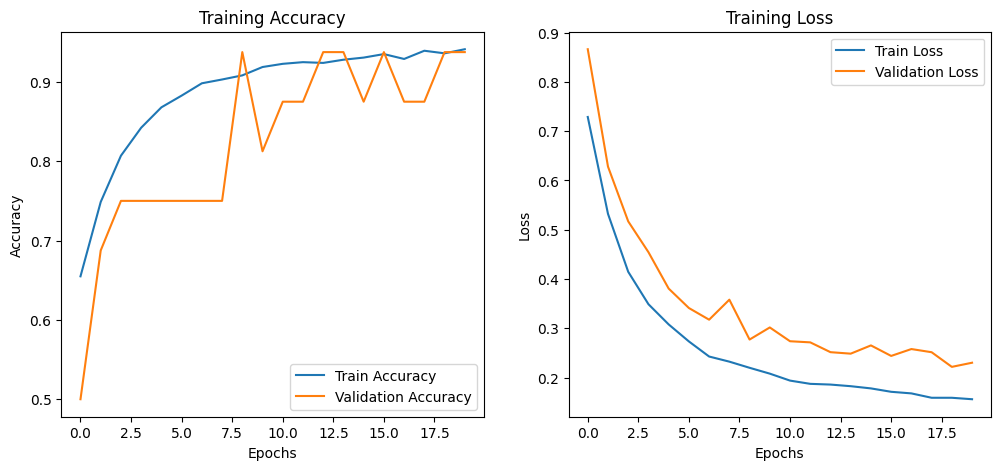

In [8]:
# Cell 7: Plot accuracy and loss curves

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 799ms/step


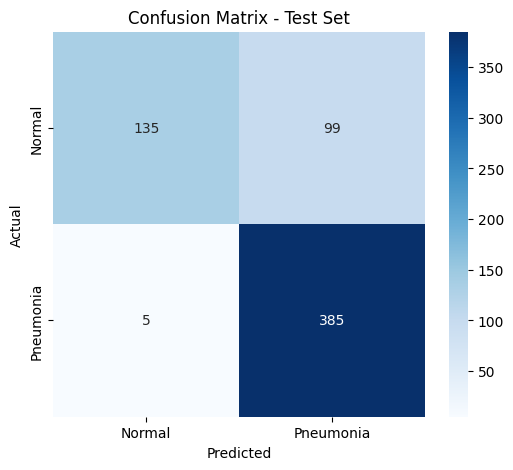

Classification Report - Test Set:
               precision    recall  f1-score   support

      Normal       0.96      0.58      0.72       234
   Pneumonia       0.80      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



In [9]:
# Cell 8: Evaluate model on test set

y_pred_probs = model.predict(test_generator)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Pneumonia'],
            yticklabels=['Normal','Pneumonia'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Test Set')
plt.show()

# Classification Report
report = classification_report(y_true, y_pred, target_names=['Normal','Pneumonia'])
print("Classification Report - Test Set:\n", report)


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step - accuracy: 0.9219 - loss: 0.1868 - val_accuracy: 0.6250 - val_loss: 0.7564
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 205s 1s/step - accuracy: 0.9436 - loss: 0.1476 - val_accuracy: 0.8125 - val_loss: 0.3807
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.9585 - loss: 0.1082 - val_accuracy: 0.9375 - val_loss: 0.2509
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 206s 1s/step - accuracy: 0.9633 - loss: 0.0999 - val_accuracy: 0.8750 - val_loss: 0.2857
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9621 - loss: 0.1051

163/163 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.9621 - loss: 0.1051 - val_accuracy: 0.9375 - val_loss: 0.1756
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.9693 - loss: 0.0825 - val_accuracy: 0.9375 - val_loss: 0.2146
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.9714 - loss: 0.0794 - val_accuracy: 0.9375 - val_loss: 0.2165
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 205s 1s/step - accuracy: 0.9730 - loss: 0.0805 - val_accuracy: 0.9375 - val_loss: 0.2002
Epoch 9/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9711 - loss: 0.0788

163/163 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.9711 - loss: 0.0788 - val_accuracy: 0.9375 - val_loss: 0.1467
Epoch 10/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9808 - loss: 0.0621 - val_accuracy: 0.9375 - val_loss: 0.1513


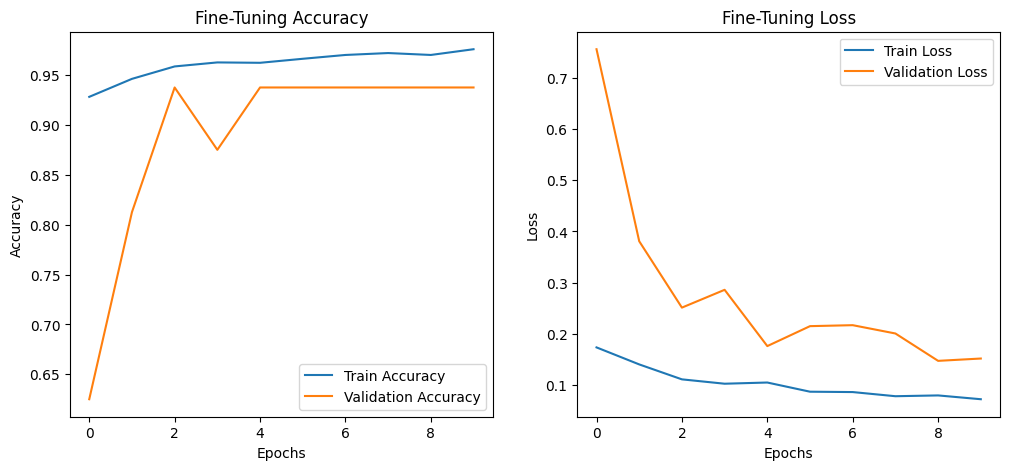

Fine-tuned MobileNet saved to /kaggle/working/mobilenet_pneumonia_finetuned.h5


In [10]:
# Cell 9: Fine-tuning top layers of MobileNet

for layer in base_model.layers[-20:]:
    layer.trainable = True

# Lower learning rate for fine-tuning
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_ft = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=callbacks
)

# Plot fine-tuning history
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_ft.history['accuracy'], label='Train Accuracy')
plt.plot(history_ft.history['val_accuracy'], label='Validation Accuracy')
plt.title('Fine-Tuning Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_ft.history['loss'], label='Train Loss')
plt.plot(history_ft.history['val_loss'], label='Validation Loss')
plt.title('Fine-Tuning Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Save fine-tuned model
MODEL_PATH = "/kaggle/working/mobilenet_pneumonia_finetuned.h5"
model.save(MODEL_PATH)
print(f"Fine-tuned MobileNet saved to {MODEL_PATH}")
